# Analisis dan Klasifikasi Gangguan Tidur

Notebook ini menganalisis faktor-faktor yang berkaitan dengan gangguan tidur, lalu membandingkan beberapa model machine learning untuk memprediksinya.

**Dataset:** `Gangguan_Tidur.csv`, 374 baris dan 13 kolom. Isinya data gaya hidup dan kesehatan (durasi dan kualitas tidur, aktivitas fisik, tingkat stres, kategori BMI, tekanan darah, detak jantung, jumlah langkah harian), ditambah jenis kelamin, umur, dan pekerjaan.

**Target:** kolom `Sleep Disorder` dengan tiga kelas:

- `None`: tidak ada gangguan tidur
- `Sleep Apnea`: gangguan pernapasan saat tidur
- `Insomnia`: sulit memulai atau mempertahankan tidur

**Alur notebook:**

1. Setup
2. Memuat dan membersihkan data
3. Exploratory Data Analysis (EDA)
4. Preprocessing
5. Modeling dan evaluasi
6. Interpretasi model
7. Kesimpulan

## 1. Setup

Semua import dan konstanta dikumpulkan di sini. `RANDOM_STATE` dipakai oleh semua komponen acak supaya hasil notebook selalu sama setiap kali dijalankan ulang.

In [1]:
import os

# Windows 11 versi baru tidak lagi menyertakan perintah `wmic`, sehingga joblib (dipakai scikit-learn)
# gagal menghitung core fisik CPU dan mencetak peringatan beserta traceback panjang. Dengan memberi batas
# jumlah core secara eksplisit, joblib tidak perlu menghitungnya. Nilai ini tidak mengubah hasil model.
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(max(1, (os.cpu_count() or 2) // 2)))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict, cross_validate
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
DATA_PATH = "Gangguan_Tidur.csv"
TARGET = "Sleep Disorder"
CLASS_NAMES = ["None", "Sleep Apnea", "Insomnia"]
LABEL_MAP = {name: i for i, name in enumerate(CLASS_NAMES)}
CAT_COLS = ["Gender", "Occupation", "BMI Category"]
NUM_COLS = [
    "Age", "Sleep Duration", "Quality of Sleep", "Physical Activity Level",
    "Stress Level", "Heart Rate", "Daily Steps", "Systolic", "Diastolic",
]

## 2. Memuat dan Membersihkan Data

Fungsi `load_data` melakukan empat hal:

1. **Membaca `"None"` sebagai teks.** Secara default pandas mengubah string `"None"` menjadi nilai kosong (NaN). Padahal di sini `None` adalah kelas yang sah (tidak ada gangguan tidur), jadi dipakai `keep_default_na=False`.
2. **Membuang `Person ID`.** Kolom ini hanya nomor urut dan tidak membawa informasi.
3. **Menyatukan `"Normal Weight"` ke `"Normal"`.** Keduanya adalah kategori BMI yang sama tetapi ditulis dengan dua cara. Tidak ada data angka BMI yang mendukung kategori "Under Weight".
4. **Memecah `Blood Pressure`** (teks seperti `"126/83"`) menjadi dua kolom angka, `Systolic` dan `Diastolic`. Versi sebelumnya mengubahnya menjadi Normal/Abnormal dengan daftar nilai yang ditulis manual. Daftar itu memasukkan 126/83 dan 128/84 sebagai "Normal", padahal menurut pedoman AHA 2017 diastolik 80–89 sudah tergolong hipertensi tahap 1. Dengan memakai angkanya langsung, tidak ada informasi yang hilang.

In [2]:
def load_data(path):
    """Membaca CSV dan merapikan kolom agar siap dianalisis."""
    data = pd.read_csv(path, keep_default_na=False)
    data = data.drop(columns="Person ID")
    data["BMI Category"] = data["BMI Category"].replace({"Normal Weight": "Normal"})
    tekanan = data["Blood Pressure"].str.split("/", expand=True).astype(int)
    data["Systolic"] = tekanan[0]
    data["Diastolic"] = tekanan[1]
    data = data.drop(columns="Blood Pressure")
    return data[[c for c in data.columns if c != TARGET] + [TARGET]]


df = load_data(DATA_PATH)
df.head()

,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Systolic,Diastolic,Sleep Disorder
0,Male,27,Software Engineer,6.1,6,42,6,Overweight,77,4200,126,83,None
1,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,125,80,None
2,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,125,80,None
3,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,140,90,Sleep Apnea
4,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,140,90,Sleep Apnea


Sel berikut adalah **pemeriksaan otomatis**. Kalau data tidak sesuai harapan, notebook berhenti di sini dengan `AssertionError`, jadi kesalahan tidak terbawa diam-diam ke analisis berikutnya.

In [3]:
assert df.shape == (374, 13)
assert df.isna().sum().sum() == 0
assert df[TARGET].value_counts().to_dict() == {"None": 219, "Sleep Apnea": 78, "Insomnia": 77}
assert set(df["BMI Category"]) == {"Normal", "Overweight", "Obese"}
assert {"Systolic", "Diastolic"} <= set(df.columns) and "Blood Pressure" not in df.columns
assert df.duplicated().sum() == 242
print("Semua pemeriksaan data lolos.")

Semua pemeriksaan data lolos.


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Gender                   374 non-null    object 
 1   Age                      374 non-null    int64  
 2   Occupation               374 non-null    object 
 3   Sleep Duration           374 non-null    float64
 4   Quality of Sleep         374 non-null    int64  
 5   Physical Activity Level  374 non-null    int64  
 6   Stress Level             374 non-null    int64  
 7   BMI Category             374 non-null    object 
 8   Heart Rate               374 non-null    int64  
 9   Daily Steps              374 non-null    int64  
 10  Systolic                 374 non-null    int64  
 11  Diastolic                374 non-null    int64  
 12  Sleep Disorder           374 non-null    object 
dtypes: float64(1), int64(8), object(4)
memory usage: 38.1+ KB


In [5]:
df.describe().round(2)

,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps,Systolic,Diastolic
count,374.00,374.00,374.00,374.00,374.00,374.00,374.00,374.00,374.00
mean,42.18,7.13,7.31,59.17,5.39,70.17,6816.84,128.55,84.65
std,8.67,0.80,1.20,20.83,1.77,4.14,1617.92,7.75,6.16
min,27.00,5.80,4.00,30.00,3.00,65.00,3000.00,115.00,75.00
25%,35.25,6.40,6.00,45.00,4.00,68.00,5600.00,125.00,80.00
50%,43.00,7.20,7.00,60.00,5.00,70.00,7000.00,130.00,85.00
75%,50.00,7.80,8.00,75.00,7.00,72.00,8000.00,135.00,90.00
max,59.00,8.50,9.00,90.00,8.00,86.00,10000.00,142.00,95.00


In [6]:
df.describe(include="object")

,Gender,Occupation,BMI Category,Sleep Disorder
count,374,374,374,374
unique,2,11,3,3
top,Male,Nurse,Normal,None
freq,189,73,216,219


### Kualitas data: baris kembar

Setelah `Person ID` dibuang, banyak baris ternyata identik. Ini penting untuk evaluasi model di Bagian 5.

In [7]:
fitur = [c for c in df.columns if c != TARGET]
baris_unik = df.drop_duplicates()
label_per_kombinasi = baris_unik.groupby(fitur)[TARGET].nunique()

print(f"Baris duplikat                       : {df.duplicated().sum()} dari {len(df)}")
print(f"Baris unik                           : {len(baris_unik)}")
print(f"Kombinasi fitur unik                 : {len(label_per_kombinasi)}")
print(f"Kombinasi fitur dengan label berbeda : {(label_per_kombinasi > 1).sum()}")

Baris duplikat                       : 242 dari 374
Baris unik                           : 132
Kombinasi fitur unik                 : 109
Kombinasi fitur dengan label berbeda : 22


Artinya:

- **242 dari 374 baris (65%) adalah duplikat.** Baris kembar tetap dipakai, karena bisa jadi memang ada beberapa orang dengan profil yang sama. Tetapi saat validasi, baris kembar **tidak boleh** berada di data latih dan data uji sekaligus. Kalau dibiarkan, model cukup "menghafal" baris itu dan skornya terlihat lebih bagus daripada kenyataannya. Bagian 4 menangani hal ini dengan validasi berbasis grup.
- **22 kombinasi fitur muncul dengan label berbeda.** Orang dengan data yang persis sama ada yang tercatat punya gangguan tidur, ada yang tidak. Jadi tidak ada model yang bisa mencapai akurasi 100% pada data ini.

## 3. Exploratory Data Analysis (EDA)

Bagian ini hanya membaca data, tidak mengubah `df`. Setiap kelas gangguan tidur diberi warna yang sama di semua grafik.

In [8]:
PALETTE = dict(zip(CLASS_NAMES, sns.color_palette("deep", n_colors=3)))

### 3.1 Distribusi target

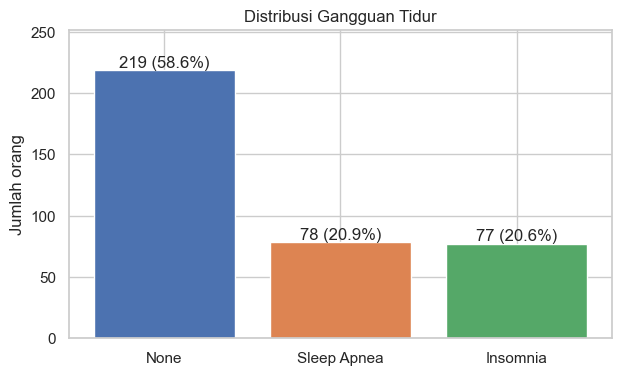

In [9]:
jumlah = df[TARGET].value_counts().reindex(CLASS_NAMES)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(jumlah.index, jumlah.values, color=[PALETTE[c] for c in CLASS_NAMES])
ax.bar_label(bars, labels=[f"{n} ({n / len(df):.1%})" for n in jumlah])
ax.set_title("Distribusi Gangguan Tidur")
ax.set_ylabel("Jumlah orang")
ax.set_ylim(0, jumlah.max() * 1.15)
plt.show()

**Insight:** 58,6% orang tidak punya gangguan tidur. Sleep Apnea (20,9%) dan Insomnia (20,6%) jumlahnya hampir sama. Kelasnya tidak seimbang, jadi model yang selalu menebak "None" pun sudah mendapat akurasi 58,6%. Karena itu evaluasi model di Bagian 5 juga memakai **macro-F1**, yang memberi bobot sama untuk ketiga kelas.

### 3.2 Distribusi fitur numerik

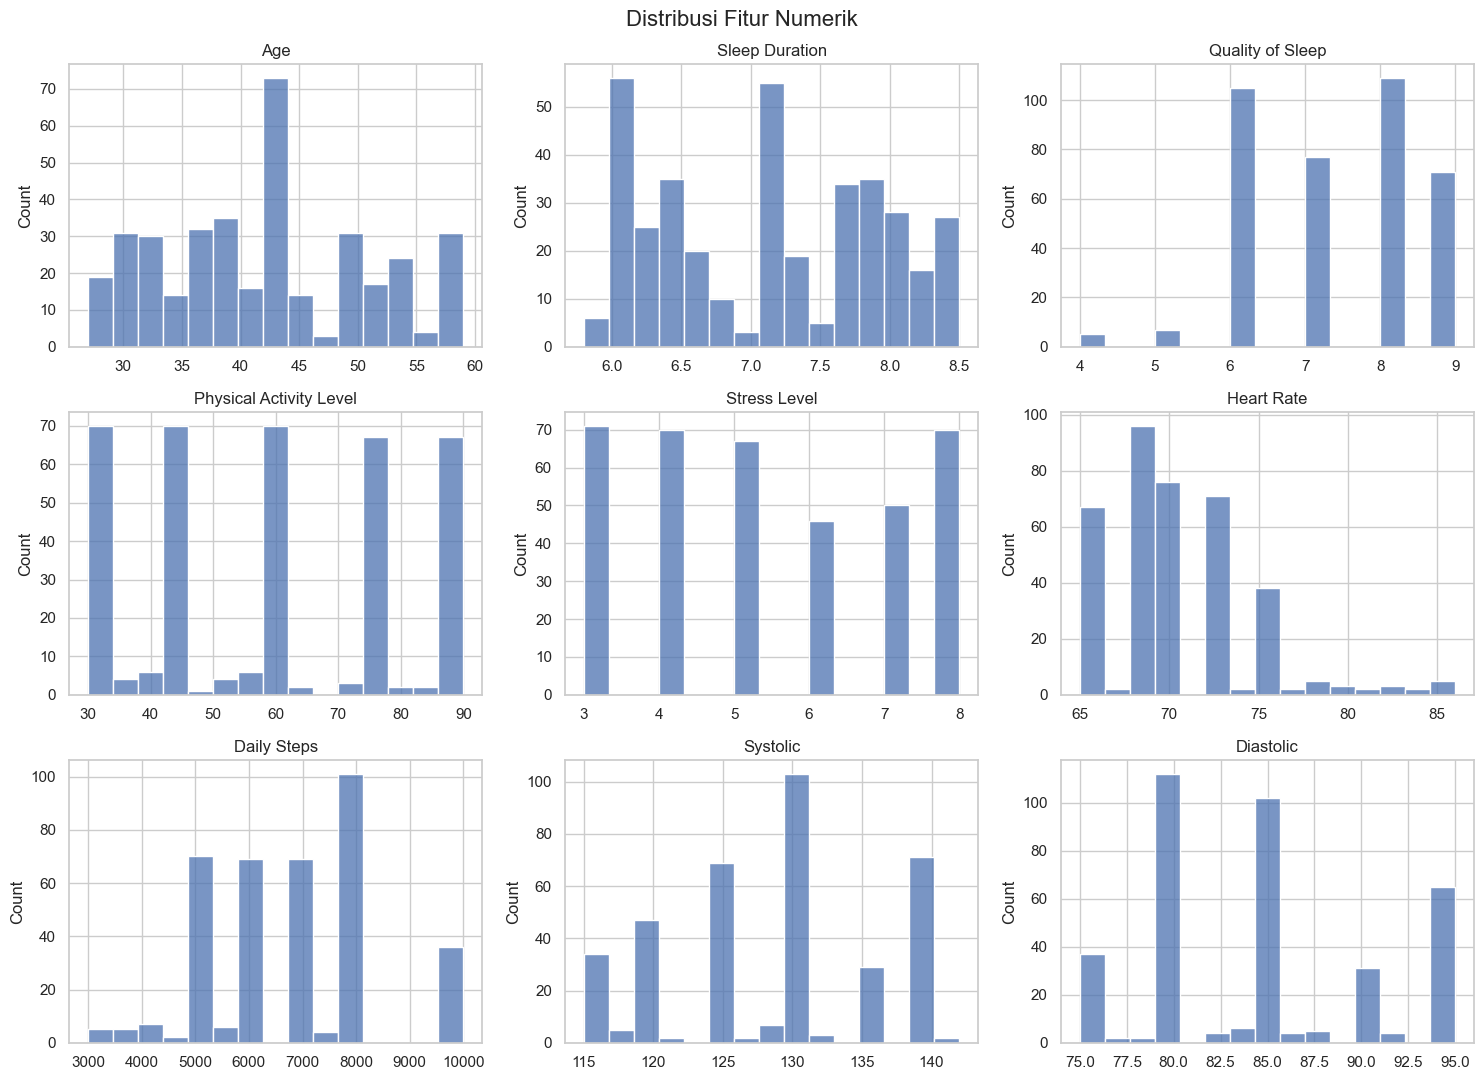

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.flat, NUM_COLS):
    sns.histplot(data=df, x=col, bins=15, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Distribusi Fitur Numerik", fontsize=16)
plt.tight_layout()
plt.show()

Sebagian besar fitur hanya punya sedikit nilai yang berbeda (misalnya `Quality of Sleep` dan `Stress Level` hanya berisi 6 nilai, dan `Daily Steps` didominasi angka bulat seperti 5000, 7000, 8000). Ini ciri khas data sintetis. Nilai-nilai di ujung distribusi tetap wajar secara medis, sehingga **tidak ada baris yang dibuang sebagai outlier**.

### 3.3 Distribusi fitur kategorikal

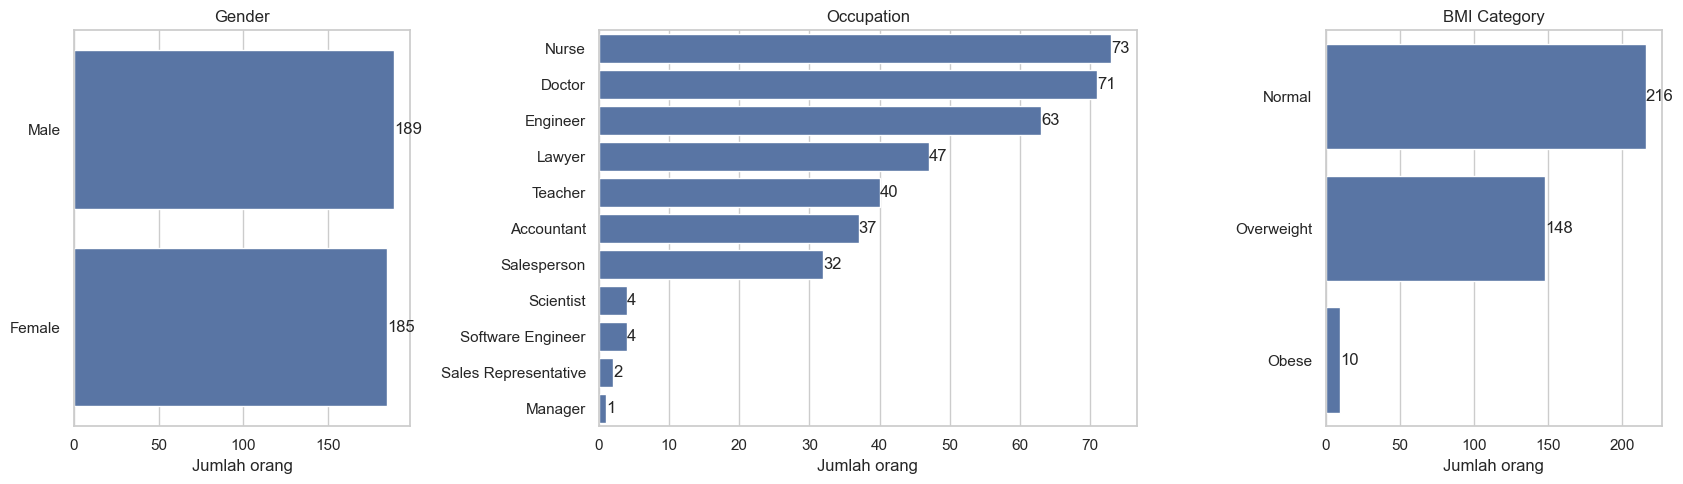

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1, 1.6, 1]})
for ax, col in zip(axes, CAT_COLS):
    urutan = df[col].value_counts().index
    sns.countplot(data=df, y=col, order=urutan, color=sns.color_palette("deep")[0], ax=ax)
    ax.bar_label(ax.containers[0])
    ax.set_title(col)
    ax.set_xlabel("Jumlah orang")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

Jumlah laki-laki dan perempuan seimbang. Pada `Occupation`, empat pekerjaan (Scientist, Software Engineer, Sales Representative, Manager) masing-masing hanya punya 1–4 orang, sehingga pola pada kelompok tersebut tidak bisa disimpulkan.

### 3.4 Fitur numerik per kelas gangguan tidur

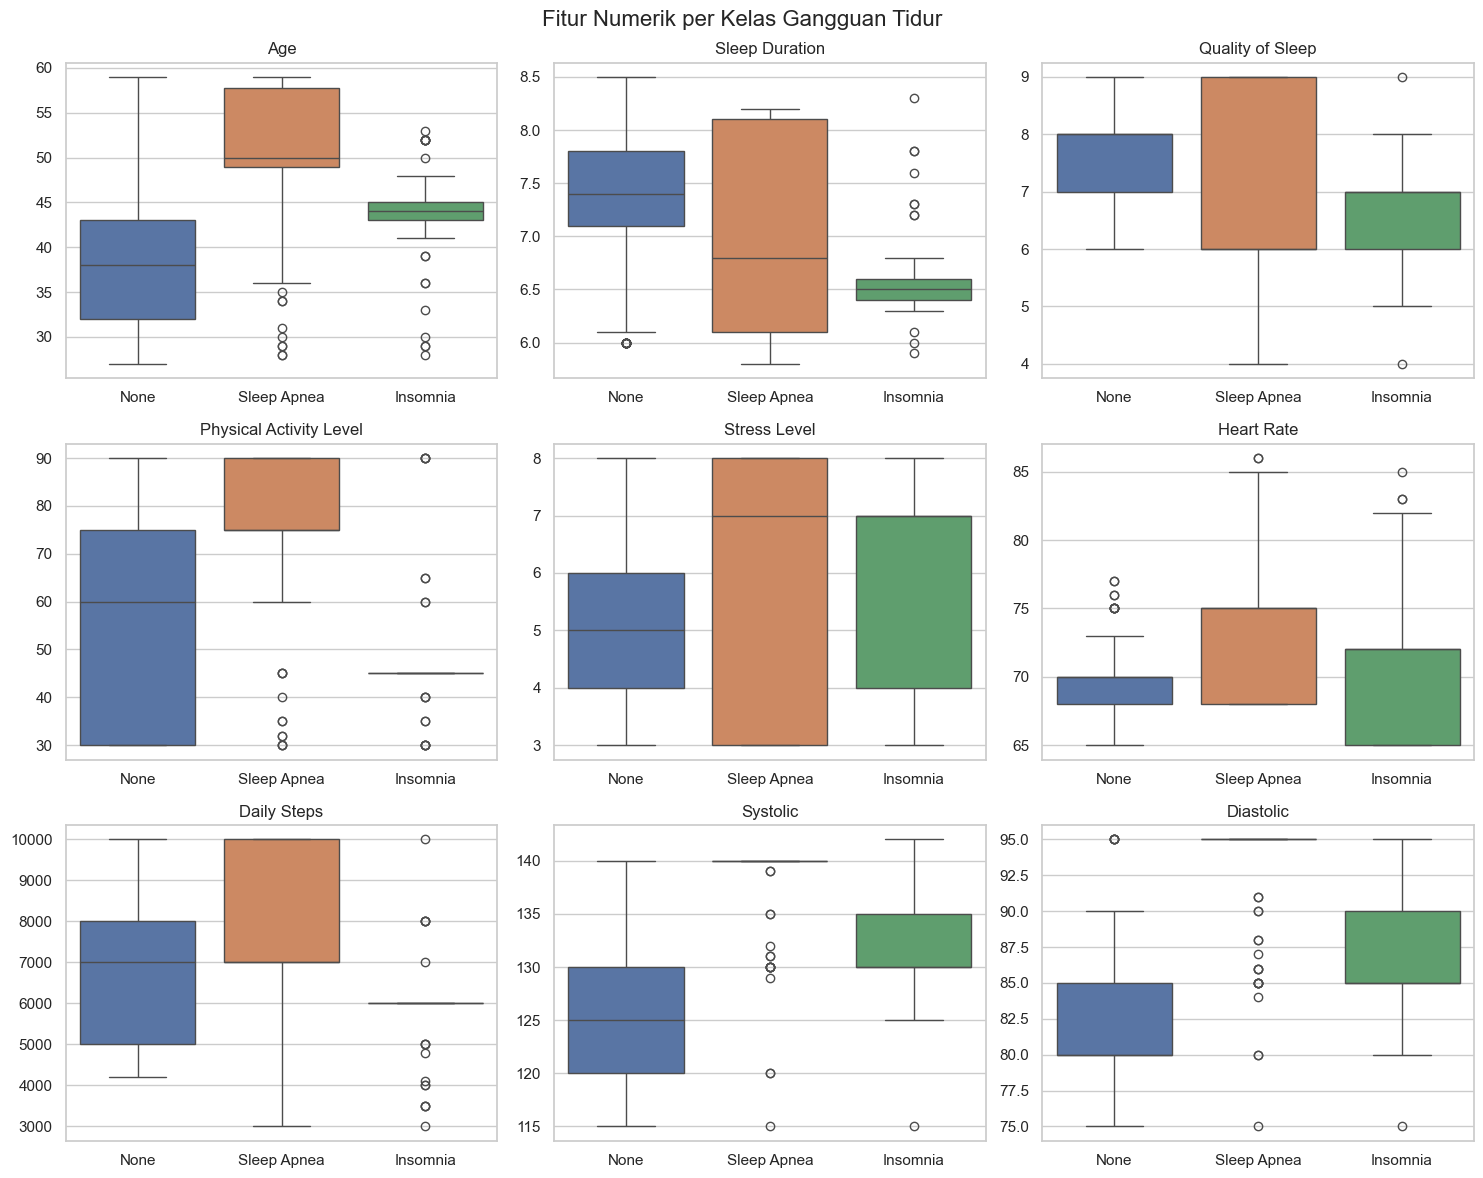

In [12]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, col in zip(axes.flat, NUM_COLS):
    sns.boxplot(
        data=df, x=TARGET, y=col, order=CLASS_NAMES,
        hue=TARGET, hue_order=CLASS_NAMES, palette=PALETTE, legend=False, ax=ax,
    )
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("Fitur Numerik per Kelas Gangguan Tidur", fontsize=16)
plt.tight_layout()
plt.show()

In [13]:
df.groupby(TARGET)[NUM_COLS].median().loc[CLASS_NAMES].T

Sleep Disorder,None,Sleep Apnea,Insomnia
Age,38.0,50.0,44.0
Sleep Duration,7.4,6.8,6.5
Quality of Sleep,8.0,6.0,7.0
Physical Activity Level,60.0,75.0,45.0
Stress Level,5.0,7.0,7.0
Heart Rate,70.0,75.0,72.0
Daily Steps,7000.0,7000.0,6000.0
Systolic,125.0,140.0,130.0
Diastolic,80.0,95.0,85.0


**Insight (berdasarkan median):**

- **Tidur:** kelompok tanpa gangguan tidur paling lama (7,4 jam) dan kualitasnya paling baik (8). Kelompok Insomnia tidur paling singkat (6,5 jam).
- **Stres:** median tingkat stres kedua kelompok gangguan tidur adalah 7, sedangkan kelompok tanpa gangguan 5.
- **Tekanan darah:** Sleep Apnea paling tinggi (140/95), disusul Insomnia (130/85), lalu tanpa gangguan (125/80). Detak jantung juga paling tinggi pada Sleep Apnea (75).
- **Umur:** penderita Sleep Apnea cenderung lebih tua (median 50 tahun) dibanding Insomnia (44) dan tanpa gangguan (38).
- **Aktivitas:** Insomnia punya aktivitas fisik (45) dan langkah harian (6000) paling rendah. Sebaliknya, aktivitas fisik Sleep Apnea justru paling tinggi (75). Temuan ini perlu dibaca hati-hati, karena kelompok Sleep Apnea didominasi satu profesi (Nurse, lihat 3.5).

### 3.5 Fitur kategorikal per kelas gangguan tidur

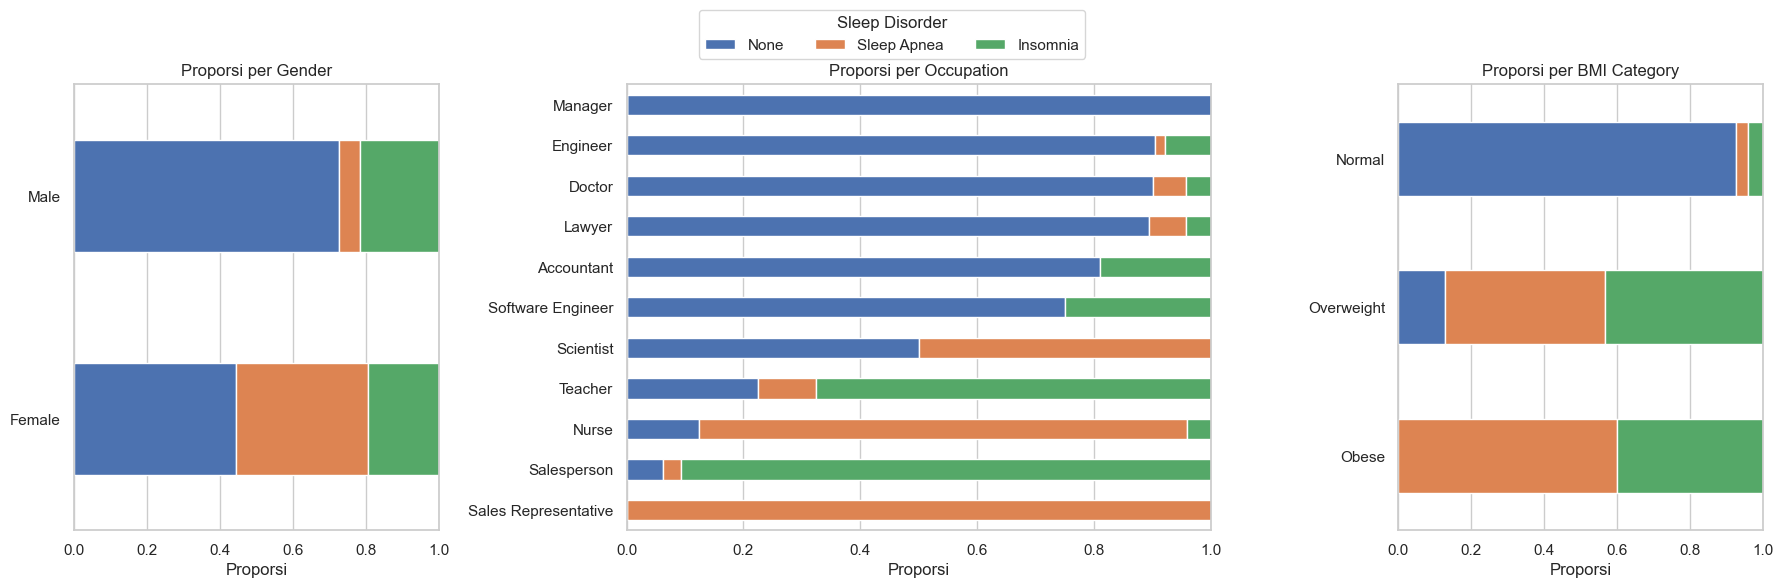

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), gridspec_kw={"width_ratios": [1, 1.6, 1]})
for ax, col in zip(axes, CAT_COLS):
    proporsi = pd.crosstab(df[col], df[TARGET], normalize="index")[CLASS_NAMES].sort_values("None")
    proporsi.plot(kind="barh", stacked=True, color=[PALETTE[c] for c in CLASS_NAMES], legend=False, ax=ax)
    ax.set_title(f"Proporsi per {col}")
    ax.set_xlabel("Proporsi")
    ax.set_ylabel("")
    ax.set_xlim(0, 1)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title=TARGET, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.08))
plt.tight_layout()
plt.show()

In [15]:
pd.crosstab(df["Occupation"], df[TARGET], margins=True, margins_name="Total")[CLASS_NAMES + ["Total"]] \
    .sort_values("Total", ascending=False)

Sleep Disorder,None,Sleep Apnea,Insomnia,Total
Occupation,,,,
Total,219,78,77,374
Nurse,9,61,3,73
Doctor,64,4,3,71
Engineer,57,1,5,63
Lawyer,42,3,2,47
Teacher,9,4,27,40
Accountant,30,0,7,37
Salesperson,2,1,29,32
Software Engineer,3,0,1,4


**Insight:**

- **Jenis kelamin:** Sleep Apnea jauh lebih banyak pada perempuan (67 dari 185, 36%) dibanding laki-laki (11 dari 189, 6%). Insomnia jumlahnya mirip (36 vs 41).
- **BMI:** 93% orang dengan BMI normal tidak punya gangguan tidur. Sebaliknya, 87% orang Overweight (129 dari 148) dan seluruh 10 orang Obese punya gangguan tidur.
- **Pekerjaan:** Nurse didominasi Sleep Apnea (61 dari 73). Salesperson (29 dari 32) dan Teacher (27 dari 40) didominasi Insomnia. Doctor, Engineer, dan Lawyer hampir semuanya tanpa gangguan.
- Kaitan pekerjaan dengan label sangat kuat. Model bisa saja "menebak dari pekerjaan" alih-alih dari kondisi kesehatan, jadi hasil model nanti sebaiknya tidak digeneralisasi ke populasi lain.

### 3.6 Korelasi antar fitur numerik

Dipakai korelasi **Spearman** karena beberapa fitur berupa skala urutan (kualitas tidur, tingkat stres) dan distribusinya tidak normal. Target tidak dimasukkan karena bersifat kategori, bukan angka berurutan.

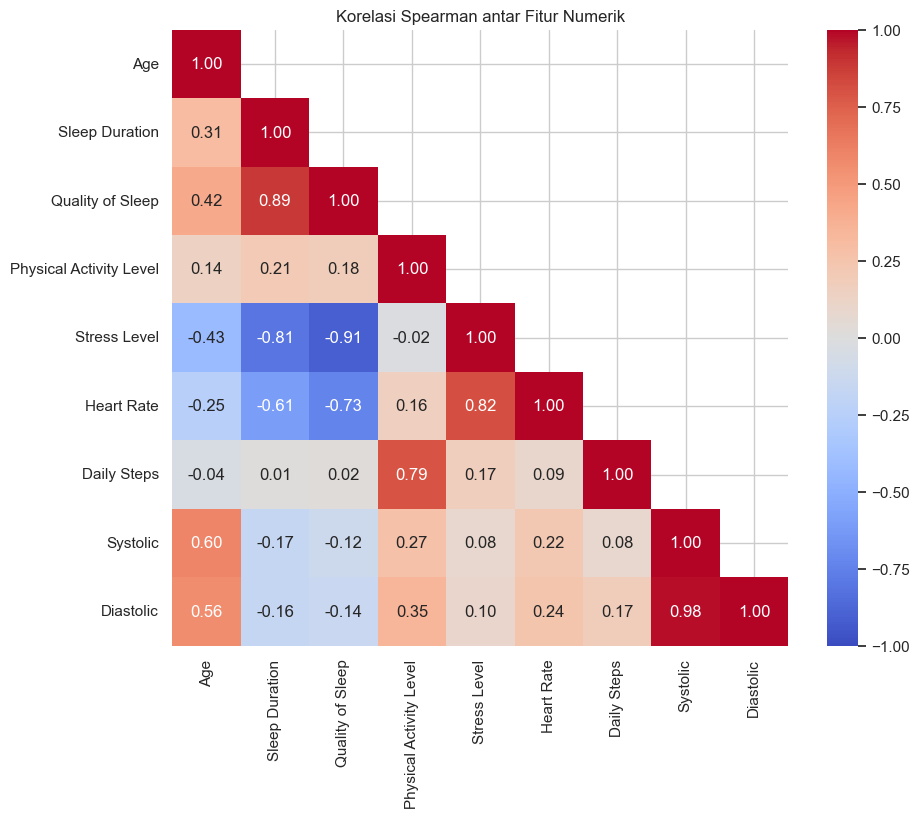

In [16]:
korelasi = df[NUM_COLS].corr(method="spearman")
segitiga_atas = np.triu(np.ones_like(korelasi, dtype=bool), k=1)

plt.figure(figsize=(10, 8))
sns.heatmap(korelasi, mask=segitiga_atas, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Korelasi Spearman antar Fitur Numerik")
plt.show()

**Insight:**

- `Systolic` dan `Diastolic` hampir identik (0,98), sehingga keduanya membawa informasi yang hampir sama.
- Kualitas tidur sangat berkaitan dengan stres (−0,91) dan durasi tidur (0,89): makin tinggi stres, makin buruk dan makin singkat tidurnya.
- Detak jantung naik seiring stres (0,82). Langkah harian sejalan dengan aktivitas fisik (0,79).

### 3.7 Hubungan fitur utama per kelas

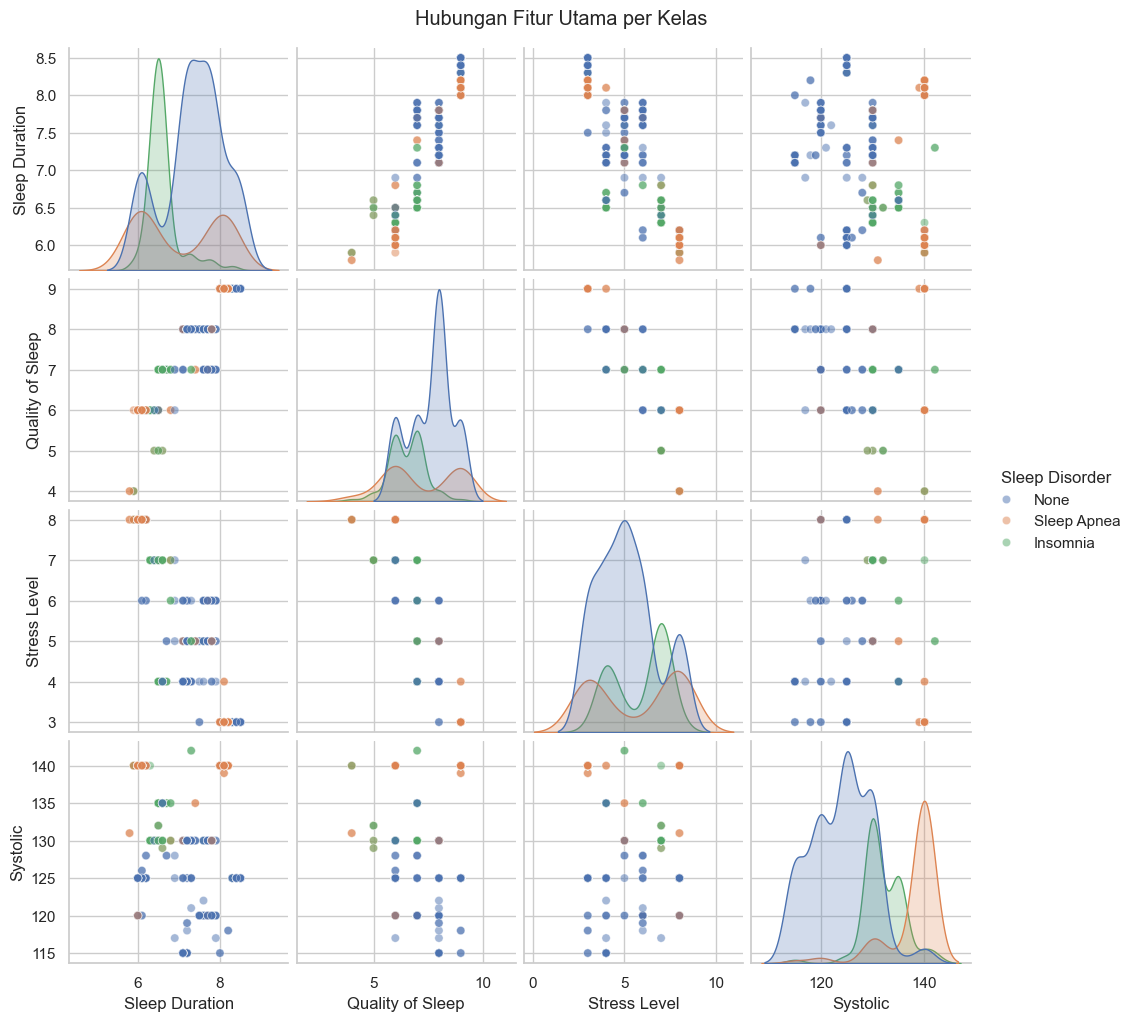

In [17]:
g = sns.pairplot(
    df,
    vars=["Sleep Duration", "Quality of Sleep", "Stress Level", "Systolic"],
    hue=TARGET, hue_order=CLASS_NAMES, palette=PALETTE,
    plot_kws={"alpha": 0.5},
)
g.figure.suptitle("Hubungan Fitur Utama per Kelas", y=1.02)
plt.show()

### Ringkasan EDA

- Gangguan tidur berkaitan dengan **tidur yang lebih singkat dan berkualitas rendah, stres tinggi, tekanan darah tinggi, dan BMI berlebih**.
- **Sleep Apnea** paling menonjol lewat tekanan darah tinggi, usia lebih tua, dan dominasi perempuan/Nurse.
- **Insomnia** paling menonjol lewat durasi tidur paling singkat dan aktivitas fisik paling rendah.
- Pola-pola ini sangat rapi untuk ukuran data kesehatan. Ini wajar untuk dataset sintetis, tetapi berarti hasil model di bagian berikutnya kemungkinan lebih optimis dibanding jika diterapkan pada data nyata.

## 4. Preprocessing

**Fitur dan target.** `X` berisi 12 fitur. `y` berisi label angka: 0 = None, 1 = Sleep Apnea, 2 = Insomnia.

**Transformasi fitur** (`make_preprocessor`):

- Kolom kategorikal diubah menjadi kolom 0/1 (one-hot). `handle_unknown="ignore"` mencegah error ketika suatu kategori langka, misalnya `Manager` yang hanya 1 orang, tidak muncul di data latih suatu fold.
- Kolom numerik diskalakan ke rentang 0–1 (MinMax). `clip=True` menjaga nilai data uji tetap di rentang itu, karena Multinomial Naive Bayes menolak nilai negatif.
- Transformasi ini dipasang **di dalam pipeline** model. Dengan begitu skala hanya dipelajari dari data latih setiap fold, dan informasi data uji tidak bocor ke proses pelatihan.

**Skema validasi** (`CV`): `StratifiedGroupKFold` dengan 5 fold. Setiap kelompok baris kembar (fitur identik) dijadikan satu grup, sehingga satu grup selalu berada utuh di data latih **atau** data uji, tidak pernah di keduanya. Proporsi kelas di setiap fold diusahakan mirip, dan urutan data diacak (`shuffle=True`) karena file CSV terurut.

In [18]:
X = df.drop(columns=TARGET)
y = df[TARGET].map(LABEL_MAP)
groups = X.groupby(list(X.columns)).ngroup()


def make_preprocessor(scale_numeric=True):
    """One-hot untuk kolom kategorikal; kolom numerik diskalakan ke 0–1 (atau dibiarkan apa adanya)."""
    numerik = MinMaxScaler(clip=True) if scale_numeric else "passthrough"
    return ColumnTransformer(
        [
            ("kategorikal", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
            ("numerik", numerik, NUM_COLS),
        ],
        verbose_feature_names_out=False,
    )


CV = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Pemeriksaan otomatis untuk preprocessing dan skema validasi:

- ukuran `X` dan label `y` benar;
- jumlah grup sama dengan jumlah kombinasi fitur unik (109);
- preprocessor yang hanya melihat 100 baris pertama tetap menghasilkan nilai 0–1 untuk seluruh data, termasuk kategori dan nilai yang belum pernah dilihatnya;
- tidak ada grup yang muncul di data latih dan data uji sekaligus.

In [19]:
assert X.shape == (374, 12)
assert set(y.unique()) == {0, 1, 2}
assert groups.nunique() == 109
Xt = make_preprocessor().fit(X.iloc[:100]).transform(X)
assert Xt.min() >= 0 and Xt.max() <= 1
for trn, val in CV.split(X, y, groups):
    assert set(groups.iloc[trn]).isdisjoint(groups.iloc[val])
print("Semua pemeriksaan preprocessing lolos.")

Semua pemeriksaan preprocessing lolos.


In [20]:
print(f"Jumlah fitur setelah preprocessing : {len(make_preprocessor().fit(X).get_feature_names_out())}")
print(f"Jumlah grup baris kembar           : {groups.nunique()} (grup terbesar berisi {groups.value_counts().max()} baris)\n")
for i, (trn, val) in enumerate(CV.split(X, y, groups), start=1):
    proporsi = y.iloc[val].value_counts(normalize=True).reindex([0, 1, 2]).round(2).tolist()
    print(f"Fold {i}: {len(trn)} baris latih, {len(val)} baris uji, proporsi kelas uji (None/Apnea/Insomnia) = {proporsi}")

Jumlah fitur setelah preprocessing : 25
Jumlah grup baris kembar           : 109 (grup terbesar berisi 13 baris)

Fold 1: 318 baris latih, 56 baris uji, proporsi kelas uji (None/Apnea/Insomnia) = [0.8, 0.12, 0.07]
Fold 2: 290 baris latih, 84 baris uji, proporsi kelas uji (None/Apnea/Insomnia) = [0.65, 0.1, 0.25]
Fold 3: 299 baris latih, 75 baris uji, proporsi kelas uji (None/Apnea/Insomnia) = [0.63, 0.2, 0.17]
Fold 4: 299 baris latih, 75 baris uji, proporsi kelas uji (None/Apnea/Insomnia) = [0.45, 0.33, 0.21]
Fold 5: 290 baris latih, 84 baris uji, proporsi kelas uji (None/Apnea/Insomnia) = [0.45, 0.27, 0.27]


Proporsi kelas antar fold tidak bisa persis sama, karena ada grup baris kembar yang besar (sampai 13 baris) dan satu grup tidak boleh dipecah. Akibatnya skor antar fold akan sedikit berfluktuasi. Itulah sebabnya hasil di Bagian 5 dilaporkan sebagai **rata-rata ± standar deviasi**, bukan skor satu fold terbaik.

## 5. Modeling dan Evaluasi

Tujuh model dibandingkan dengan **hyperparameter yang sama seperti versi sebelumnya**, supaya perbedaan hasil hanya berasal dari perbaikan cara evaluasi. Semua model:

- memakai pipeline preprocessing yang sama (`make_preprocessor`);
- divalidasi dengan skema `CV` yang sama (5 fold berbasis grup);
- memakai `random_state` yang sama, sehingga hasilnya bisa direproduksi.

Metrik yang dilaporkan adalah **akurasi** dan **macro-F1**, masing-masing sebagai rata-rata ± standar deviasi dari 5 fold. Model diurutkan berdasarkan macro-F1, karena metrik ini tidak bisa "dicurangi" dengan selalu menebak kelas mayoritas.

In [21]:
MODELS = {
    "Gaussian NB": GaussianNB(),
    "Multinomial NB": MultinomialNB(),
    "SVM (linear)": SVC(kernel="linear", random_state=RANDOM_STATE),
    "KNN (k=32)": KNeighborsClassifier(n_neighbors=32),
    "Decision Tree": DecisionTreeClassifier(criterion="entropy", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, criterion="entropy", random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(random_state=RANDOM_STATE),
}


def evaluate_model(model, X, y, groups, cv):
    """Cross-validation satu model: skor rata-rata ± std dan prediksi out-of-fold."""
    pipeline = make_pipeline(make_preprocessor(), model)
    skor = cross_validate(pipeline, X, y, groups=groups, cv=cv, scoring=["accuracy", "f1_macro"])
    return {
        "acc_mean": skor["test_accuracy"].mean(),
        "acc_std": skor["test_accuracy"].std(),
        "f1_mean": skor["test_f1_macro"].mean(),
        "f1_std": skor["test_f1_macro"].std(),
        "y_pred": cross_val_predict(pipeline, X, y, groups=groups, cv=cv),
    }


hasil = {name: evaluate_model(model, X, y, groups, CV) for name, model in MODELS.items()}
predictions = {name: h.pop("y_pred") for name, h in hasil.items()}
results_df = pd.DataFrame(hasil).T.sort_values("f1_mean", ascending=False)
results_df.round(3)

,acc_mean,acc_std,f1_mean,f1_std
Multinomial NB,0.884,0.035,0.818,0.097
XGBoost,0.893,0.013,0.807,0.082
Random Forest,0.886,0.016,0.796,0.094
SVM (linear),0.878,0.032,0.795,0.109
KNN (k=32),0.860,0.051,0.779,0.114
Decision Tree,0.847,0.070,0.763,0.099
Gaussian NB,0.825,0.053,0.740,0.062


In [22]:
assert len(results_df) == 7
assert results_df["acc_mean"].between(0.5, 1.0).all()
assert results_df["f1_mean"].is_monotonic_decreasing
assert all(len(p) == len(y) for p in predictions.values())
print("Semua pemeriksaan hasil model lolos.")

Semua pemeriksaan hasil model lolos.


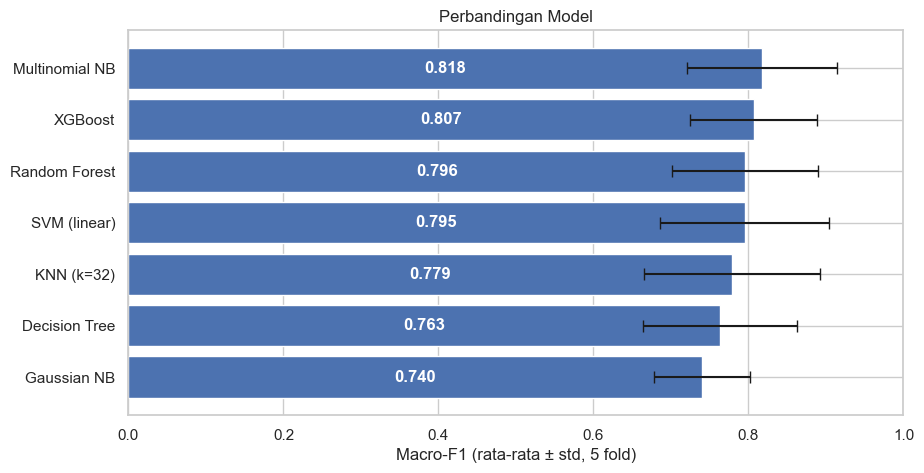

In [23]:
urut = results_df.sort_values("f1_mean")

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(urut.index, urut["f1_mean"], xerr=urut["f1_std"], capsize=4, color=sns.color_palette("deep")[0])
ax.bar_label(bars, labels=[f"{v:.3f}" for v in urut["f1_mean"]], label_type="center", color="white", fontweight="bold")
ax.set_xlim(0, 1)
ax.set_xlabel("Macro-F1 (rata-rata ± std, 5 fold)")
ax.set_title("Perbandingan Model")
plt.show()

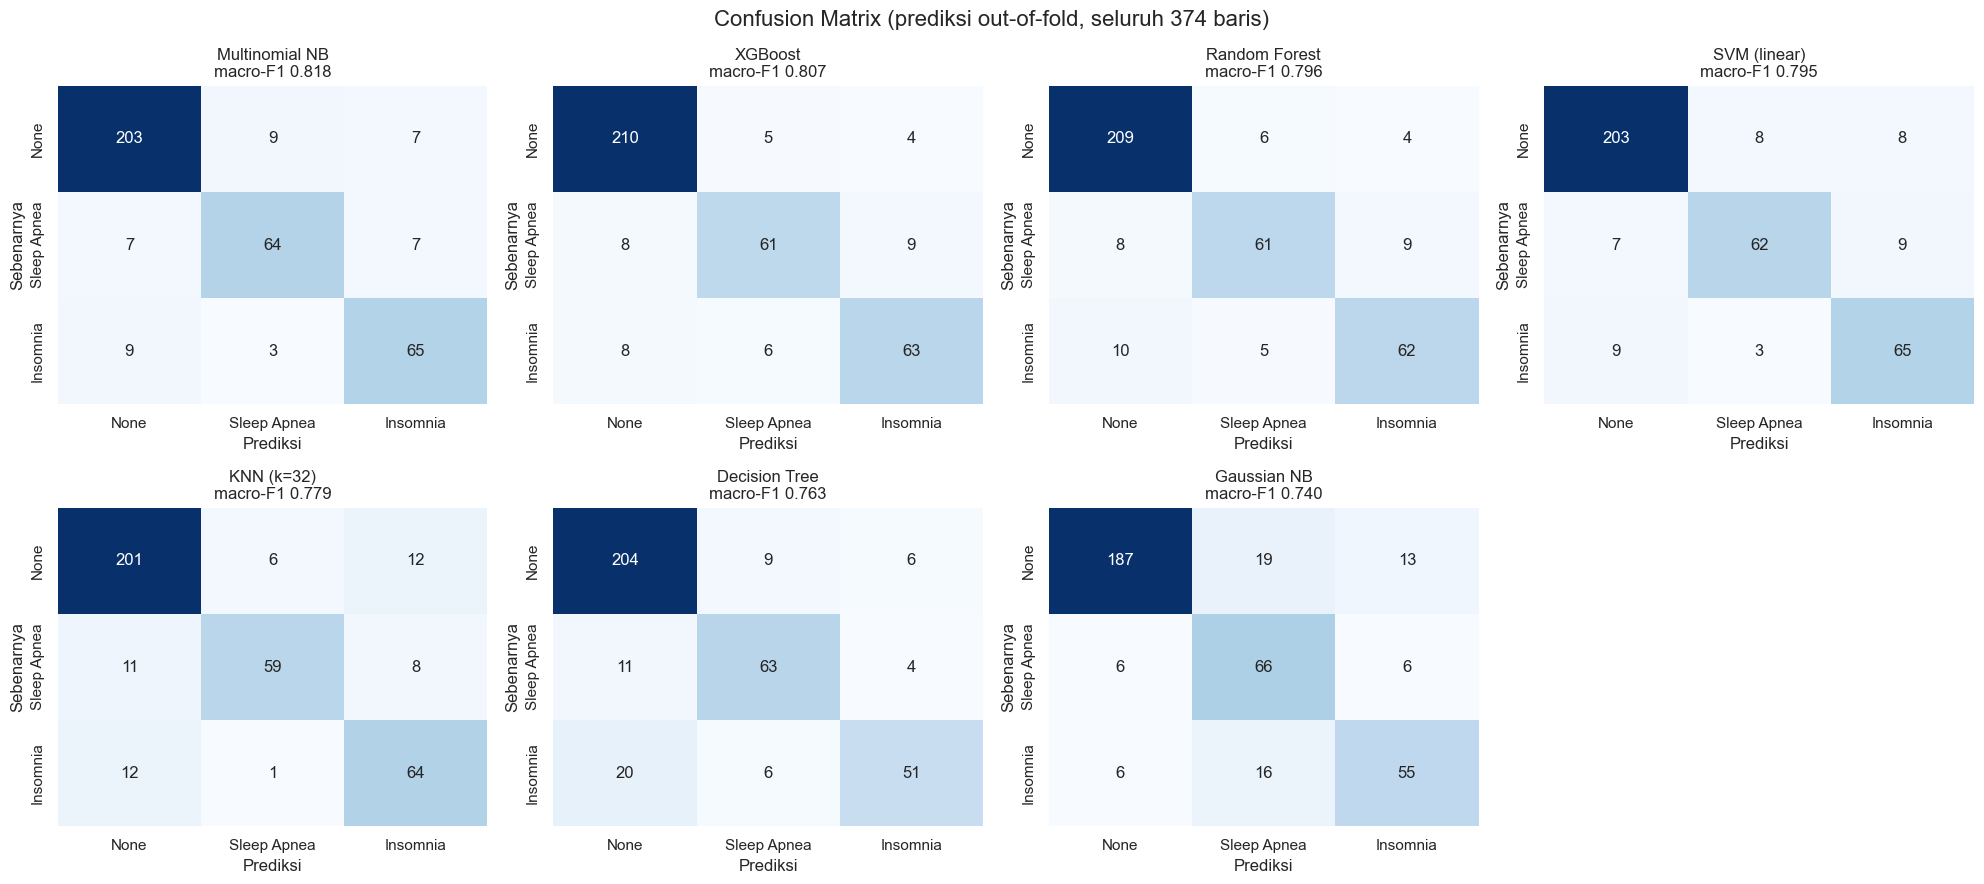

In [24]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, name in zip(axes.flat, results_df.index):
    cm = confusion_matrix(y, predictions[name], labels=[0, 1, 2])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_title(f"{name}\nmacro-F1 {results_df.loc[name, 'f1_mean']:.3f}")
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Sebenarnya")
axes.flat[-1].remove()
fig.suptitle("Confusion Matrix (prediksi out-of-fold, seluruh 374 baris)", fontsize=16)
plt.tight_layout()
plt.show()

In [25]:
model_terbaik = results_df.index[0]
print(f"Model terbaik berdasarkan macro-F1: {model_terbaik}\n")
print(classification_report(y, predictions[model_terbaik], target_names=CLASS_NAMES, digits=3))

Model terbaik berdasarkan macro-F1: Multinomial NB

              precision    recall  f1-score   support

        None      0.927     0.927     0.927       219
 Sleep Apnea      0.842     0.821     0.831        78
    Insomnia      0.823     0.844     0.833        77

    accuracy                          0.888       374
   macro avg      0.864     0.864     0.864       374
weighted avg      0.888     0.888     0.888       374



**Cara membaca hasil:**

- Empat model teratas (Multinomial NB, XGBoost, Random Forest, SVM) mencapai akurasi sekitar 0,88–0,89 dan macro-F1 sekitar 0,80–0,82. Selisih macro-F1 di antara keempatnya kurang dari 0,03, jauh lebih kecil dari standar deviasi antar fold (sekitar 0,08–0,11). Artinya keempat model ini **praktis setara** di data ini, tanpa satu pemenang yang jelas.
- Standar deviasi macro-F1 cukup besar karena ada fold yang hanya berisi sedikit pasien. Misalnya fold 1 hanya punya sekitar 7 Sleep Apnea dan 4 Insomnia, sehingga satu atau dua prediksi salah langsung menggeser skor.
- Pada model-model teratas, kesalahan tersebar di semua arah: sebagian kecil orang sehat diprediksi punya gangguan, sebagian penderita diprediksi sehat, dan sebagian Sleep Apnea tertukar dengan Insomnia.
- Gaussian NB terlalu sering menebak Sleep Apnea (35 orang dari kelas lain diprediksi Sleep Apnea). Decision Tree tanpa batas kedalaman sering melewatkan Insomnia (20 penderita Insomnia diprediksi None).
- Akurasi di `classification_report` (0,888) sedikit berbeda dari `acc_mean` di tabel (0,884), karena yang pertama dihitung dari gabungan semua prediksi sekaligus, sedangkan yang kedua adalah rata-rata dari 5 fold.

### Perbandingan dengan versi sebelumnya

Versi sebelumnya memakai `StratifiedKFold` **tanpa shuffle** untuk enam model, sedangkan Multinomial NB sendirian memakai shuffle. Karena file CSV terurut, setiap fold berisi kelompok orang yang sangat berbeda dengan data latihnya. Akibatnya model berbasis pohon terlihat jauh lebih buruk daripada kenyataannya.

In [26]:
akurasi_lama = pd.Series({
    "Gaussian NB": 0.837, "Multinomial NB": 0.896, "SVM (linear)": 0.834, "KNN (k=32)": 0.877,
    "Decision Tree": 0.711, "Random Forest": 0.719, "XGBoost": 0.582,
})
pd.DataFrame({
    "Akurasi versi lama": akurasi_lama,
    "Akurasi sekarang": results_df["acc_mean"],
    "Macro-F1 sekarang": results_df["f1_mean"],
}).loc[results_df.index].round(3)

,Akurasi versi lama,Akurasi sekarang,Macro-F1 sekarang
Multinomial NB,0.896,0.884,0.818
XGBoost,0.582,0.893,0.807
Random Forest,0.719,0.886,0.796
SVM (linear),0.834,0.878,0.795
KNN (k=32),0.877,0.860,0.779
Decision Tree,0.711,0.847,0.763
Gaussian NB,0.837,0.825,0.740


Dengan validasi yang adil, XGBoost naik dari 0,58 menjadi 0,89, dan Random Forest dari 0,72 menjadi 0,89. Kesimpulan lama bahwa "model berbasis pohon paling buruk" ternyata hanya akibat cara validasinya. Akurasi Multinomial NB sedikit turun, karena sekarang baris kembar tidak lagi bisa bocor dari data latih ke data uji.

## 6. Interpretasi Model

Untuk melihat fitur apa yang paling dipakai model, dua model **di-fit ulang pada seluruh data**:

- **Random Forest**, untuk melihat feature importance;
- **Decision Tree dengan kedalaman maksimum 3**, untuk melihat aturan keputusan yang bisa dibaca manusia.

Di sini kolom numerik tidak diskalakan (`scale_numeric=False`), sehingga ambang batas pada pohon tetap dalam satuan aslinya (jam, mmHg, dan seterusnya). Model berbasis pohon memang tidak terpengaruh oleh skala.

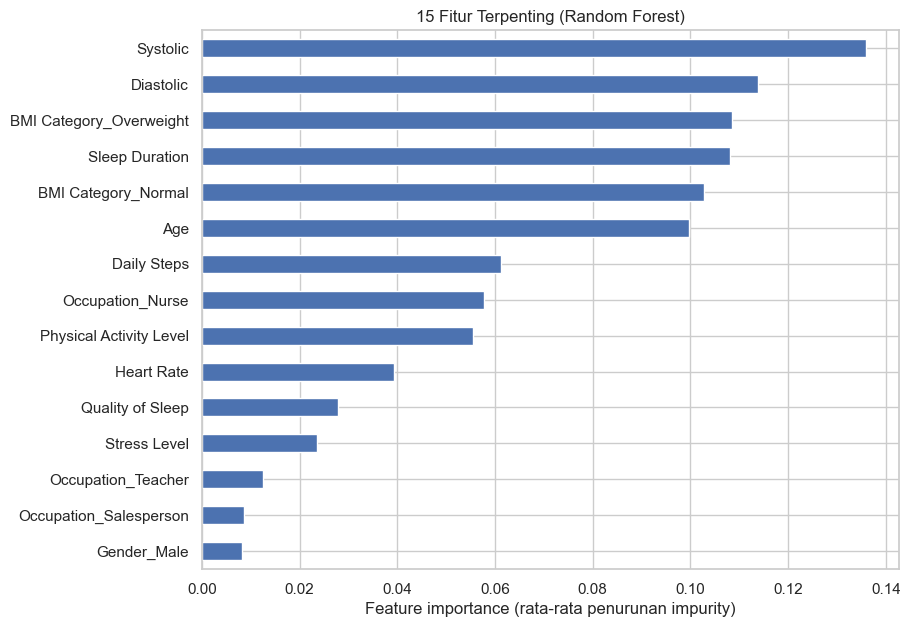

In [27]:
rf_pipeline = make_pipeline(make_preprocessor(scale_numeric=False), clone(MODELS["Random Forest"])).fit(X, y)
importance = pd.Series(
    rf_pipeline[-1].feature_importances_,
    index=rf_pipeline[:-1].get_feature_names_out(),
).sort_values()

fig, ax = plt.subplots(figsize=(9, 7))
importance.tail(15).plot(kind="barh", color=sns.color_palette("deep")[0], ax=ax)
ax.set_title("15 Fitur Terpenting (Random Forest)")
ax.set_xlabel("Feature importance (rata-rata penurunan impurity)")
plt.show()

**Insight:** tekanan darah (`Systolic`, `Diastolic`), kategori BMI, durasi tidur, dan umur adalah fitur yang paling banyak dipakai Random Forest. `Quality of Sleep` dan `Stress Level` terlihat rendah, tetapi bukan berarti tidak penting. Keduanya berkorelasi sangat kuat dengan `Sleep Duration` (lihat 3.6), sehingga "jatah" kepentingannya terbagi ke fitur tersebut. `Occupation_Nurse` juga muncul di 10 besar, sesuai temuan EDA bahwa profesi ini didominasi Sleep Apnea.

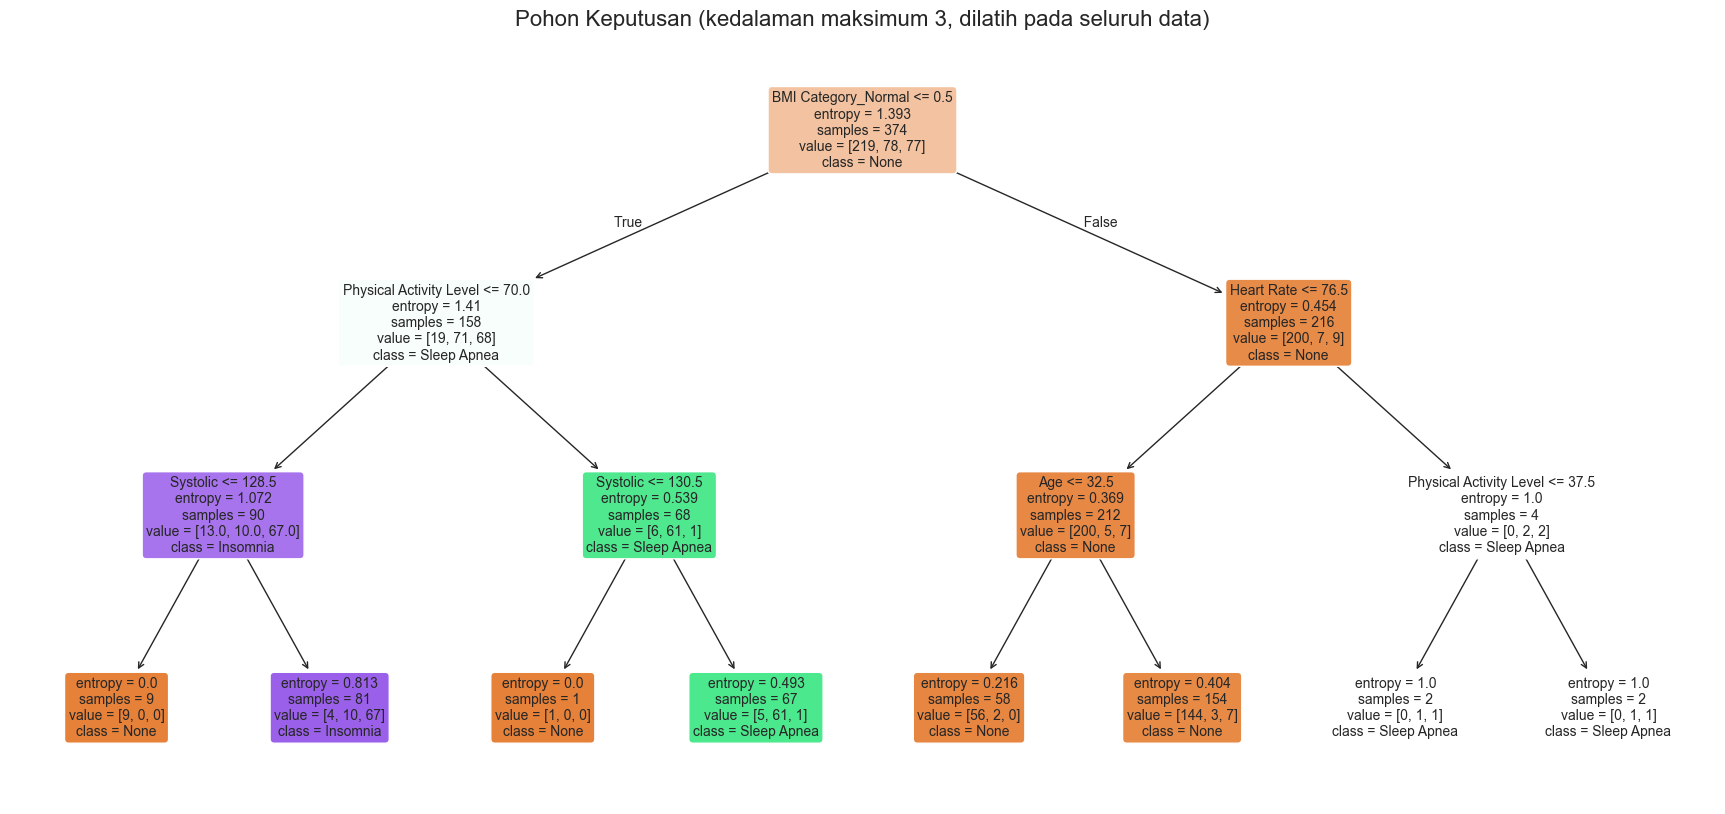

In [28]:
tree_pipeline = make_pipeline(
    make_preprocessor(scale_numeric=False),
    DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=RANDOM_STATE),
).fit(X, y)

fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(
    tree_pipeline[-1],
    feature_names=tree_pipeline[:-1].get_feature_names_out(),
    class_names=CLASS_NAMES,
    filled=True, rounded=True, fontsize=10, ax=ax,
)
ax.set_title("Pohon Keputusan (kedalaman maksimum 3, dilatih pada seluruh data)", fontsize=16)
plt.show()

**Cara membaca pohon:** setiap kotak menampilkan aturan pemisah, jumlah orang (`samples`), dan jumlah orang per kelas (`value` = [None, Sleep Apnea, Insomnia]).

- **BMI normal** (cabang kanan): 200 dari 216 orang tidak punya gangguan tidur.
- **BMI berlebih dengan aktivitas fisik > 70 dan sistolik > 130,5**: 61 dari 67 orang menderita Sleep Apnea.
- **BMI berlebih dengan aktivitas fisik ≤ 70 dan sistolik > 128,5**: 67 dari 81 orang menderita Insomnia.

Tiga aturan sederhana ini sudah memisahkan sebagian besar kasus, dan cocok dengan temuan EDA. Aturan "aktivitas fisik tinggi mengarah ke Sleep Apnea" sebaiknya tidak dibaca sebagai hubungan sebab-akibat, karena kemungkinan besar berasal dari kelompok Nurse di dataset ini.

## 7. Kesimpulan

**Faktor yang berkaitan dengan gangguan tidur**

- **Tekanan darah dan kategori BMI** adalah pembeda terkuat. Orang dengan BMI normal hampir selalu tanpa gangguan tidur, sedangkan BMI berlebih disertai tekanan darah tinggi mengarah ke gangguan tidur.
- **Tidur singkat, kualitas tidur rendah, dan stres tinggi** menyertai kedua jenis gangguan.
- **Sleep Apnea** menonjol pada usia lebih tua dan tekanan darah paling tinggi. **Insomnia** menonjol pada durasi tidur paling singkat dan aktivitas fisik paling rendah.

**Performa model**

- Dengan validasi yang adil (berbasis grup, tanpa kebocoran baris kembar), empat model teratas mencapai akurasi sekitar 0,88–0,89 dan macro-F1 sekitar 0,80–0,82. Perbedaan di antara keempatnya lebih kecil dari variasi antar fold, jadi tidak ada satu model yang jelas lebih unggul. Multinomial NB tertinggi untuk macro-F1, XGBoost tertinggi untuk akurasi.
- Kesimpulan versi lama ("XGBoost paling buruk, 58%") disebabkan oleh validasi tanpa shuffle pada data yang terurut, bukan oleh kualitas modelnya.

**Keterbatasan**

- Dataset kecil dan kemungkinan sintetis: dari 374 baris hanya ada 132 baris unik (109 kombinasi fitur), dan 22 kombinasi fitur punya label yang saling bertentangan.
- Pekerjaan sangat terkait dengan label (Nurse → Sleep Apnea, Salesperson/Teacher → Insomnia). Model bisa bergantung pada pola ini, yang belum tentu berlaku di populasi lain.
- Hyperparameter tidak di-tuning, dan skor antar fold masih cukup bervariasi (std macro-F1 sekitar 0,06–0,11).
- Hasil ini hanya berlaku untuk dataset ini dan **bukan alat diagnosis medis**.

**Saran pengembangan**

- Tuning hyperparameter dengan *nested cross-validation* yang tetap berbasis grup.
- Melatih ulang model tanpa kolom `Occupation`, untuk melihat seberapa besar model bergantung padanya.
- Menguji model pada data kesehatan nyata.